# NOMe-HiC cellline QC plots (snakemake pipeline)

QC summary and histograms for cells processed under this snakemake workdir, using the same logic as [`s1.ipynb`](../../scnomehic_paper/s1/s1.ipynb) (`summarize_cellline_qc_from_data`).

**Inputs (per cell):**
- `04.alignment_snakemake/{prefix}.summary.txt` — Hi-C alignment stats
- `07.bistools_snakemake/qc/{prefix}/*.calmd.trinuc_methy.chrM.txt` and `chr21.txt` — methylation QC
- `07.bistools_snakemake/methylation/{prefix}/*.cyt.filtered.sort.{GCH,HCG}.6plus2.bed.gz` — site counts

**Outputs:** `QC/` tables, `figures/cellline_summary.pdf`, `QC/cellline_passed.txt`, `figures/cellline_summary.pdf`, `figures/cellline_summary_p99.pdf` (p99 cap), `figures/cellline_summary_by_batch.pdf` (full), `figures/cellline_summary_by_batch_p99.pdf` (always p99), `figures/cellline_summary_by_batch_p99_if_outlier.pdf` (p99 only if outliers)

By default all cells with completed QC outputs are included. Set `BATCHES = ['batch2', 'batch3', 'batch4']` in the discovery cell to match the paper's mixed-cellline subset.

**Methylation matrices:** `QC/methylation_matrices/methylation_matrix_{GCH,HCG}_250kb.tsv.gz`


In [ ]:
import gzip
import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import yaml
from matplotlib.backends.backend_pdf import PdfPages
from tqdm.auto import tqdm

WORKDIR = Path('/gpfs/projects/b1198/epifluidlab/yoshii/sc_nomehic_cellline/snakemake')
os.chdir(WORKDIR)

ALIGN_DIR = WORKDIR / '04.alignment_snakemake'
QC_DIR = WORKDIR / '07.bistools_snakemake' / 'qc'
METH_DIR = WORKDIR / '07.bistools_snakemake' / 'methylation'
OUT_QC = WORKDIR / 'QC'
OUT_FIG = WORKDIR / 'figures'
OUT_QC.mkdir(exist_ok=True)
OUT_FIG.mkdir(exist_ok=True)

with open('config.yaml') as f:
    CFG = yaml.safe_load(f)

THRESHOLDS = {
    'fragnum_threshold': CFG['fragnum_threshold'],
    'noncpg_threshold': CFG['noncpg_threshold'],
    'GCH_threshold': CFG['GCH_threshold'],
    'HCG_threshold': CFG['HCG_threshold'],
    'cis1kbnum_threshold': CFG['cis1kbnum_threshold'],
    # Upper bound on cisnum to drop suspected doublets (see config.yaml)
    'cisnum_max_threshold': CFG.get('cisnum_max_threshold', float('inf')),
}
print('Workdir:', WORKDIR)
print('QC thresholds:', THRESHOLDS)

Workdir: /gpfs/projects/b1198/epifluidlab/yoshii/sc_nomehic_cellline/snakemake
QC thresholds: {'fragnum_threshold': 100000, 'noncpg_threshold': 5, 'GCH_threshold': 1000000, 'HCG_threshold': 150000, 'cis1kbnum_threshold': 2000, 'cisnum_max_threshold': 3000000}


In [ ]:
def summarize_cellline_qc_from_data(
    prefixes,
    gch_hcg_df,
    chrm_df,
    chr21_df,
    summary_files,
    dataset_label='mixed cellline',
    output_file=None,
    summary_pdf=None,
    utilized_cell_output=None,
    fragnum_threshold=800000,
    noncpg_threshold=3,
    GCH_threshold=1_000_000,
    HCG_threshold=150_000,
    cis1kbnum_threshold=2000,
    cisnum_max_threshold=float('inf'),   # upper bound to drop suspected doublets
    show_inline=False,
    summary_pdf_p99=None,
    clip_percentile_p99=99,
    clip_only_if_outlier=True,
):
    """
    Summarize QC metrics from in-memory data for NOMe-HiC cellline analysis.

    Parameters
    ----------
    prefixes : list[str]
        List of sample prefixes (e.g., ['batch1.sc10.ACTTGA', ...])
    gch_hcg_df : pd.DataFrame
        DataFrame with index=sample, columns=['GCH', 'HCG']
    chrm_df : pd.DataFrame
        DataFrame with index=sample, columns=['noncpg', 'endo', 'exo']
    summary_files : list[str]
        List of paths to alignment summary files (same order as prefixes)
    dataset_label : str
        Dataset name label (default 'mixed cellline')
    output_file, summary_pdf, utilized_cell_output : str or None
        Optional output paths for saving results
    *_threshold : numeric
        Filtering thresholds
    show_inline : bool
        If True, display plots inline in Jupyter

    Returns
    -------
    df_all : pd.DataFrame
        All QC metrics
    df_passed : pd.DataFrame
        QC-passing subset
    """

    def plot_hist(
        df,
        column,
        title,
        xlabel,
        pdf=None,
        threshold=None,
        clip_percentile=None,
        clip_only_if_outlier=False,
    ):
        plt.figure(figsize=(8, 5))
        subset = df[column].dropna()
        if subset.empty:
            plt.close()
            return

        plot_vals = subset
        title_use = title
        bins = 50

        if clip_percentile is not None:
            x_hi = np.percentile(subset, clip_percentile)
            n_above = int((subset > x_hi).sum())
            apply_clip = n_above > 0 if clip_only_if_outlier else True
            if apply_clip:
                plot_vals = subset[subset <= x_hi]
                x_lo = plot_vals.min()
                bins = np.linspace(x_lo, x_hi, 51)
                if n_above > 0:
                    title_use = (
                        f"{title} (x ≤ p{clip_percentile:.0f}={x_hi:.4g}; "
                        f"{n_above} above)"
                    )

        plt.hist(
            plot_vals,
            bins=bins,
            alpha=0.7,
            color='steelblue',
            edgecolor='black',
        )
        if threshold is not None:
            plt.axvline(
                threshold,
                color='red',
                linestyle='--',
                linewidth=1.5,
                label='threshold',
            )
        plt.title(title_use)
        plt.xlabel(xlabel)
        plt.ylabel('Frequency')
        if threshold is not None:
            plt.legend()
        if pdf:
            pdf.savefig()
        if show_inline:
            plt.show()
        plt.close()
    chrm_df.columns = ['noncpg_chrM','endo_chrM','exo_chrM']
    # --- Parse summaries ---
    all_entries = []
    for prefix, summ_path in tqdm(zip(prefixes, summary_files), total=len(prefixes), desc="Parsing QC summaries"):
        entry = {"prefix": prefix, "dataset": dataset_label}
        try:
            align_df = pd.read_csv(summ_path, sep='\t', header=None)
            entry.update({
                'uniquemap': float(align_df[align_df[0]=='UniqMapped:'][2].values[0].strip('%')),
                'mapq30rate': float(align_df[align_df[0]=='UniqMappedMapQ30:'][2].values[0].strip('%')),
                'mapq30num': int(align_df[align_df[0]=='UniqMappedMapQ30:'][1].values[0]),
                'fragnum': int(align_df[align_df[0]=='TotalFragments:'][1].values[0]),
                'cisnum':int(align_df[align_df[0]=='UniqMappedMapQ30NoPcrCis:'][1].values[0]), 
                'cis1kbnum': int(align_df[align_df[0]=='UniqMappedMapQ30NoPcrCisMore1kb:'][1].values[0]),
                'transnum': int(align_df[align_df[0]=='UniqMappedMapQ30NoPcrTrans:'][1].values[0]),
                'cis1kbrate': float(align_df[align_df[0]=='UniqMappedMapQ30NoPcrCisMore1kb:'][2].values[0].strip('%')),
                'transrate': float(align_df[align_df[0]=='UniqMappedMapQ30NoPcrTrans:'][2].values[0].strip('%')),
            })
        except Exception:
            entry.update({k: np.nan for k in [
                'uniquemap','mapq30rate','mapq30num','fragnum','cisnum','cis1kbnum','transnum','cis1kbrate','transrate'
            ]})

        # Add methylation and GCH/HCG data
        if prefix in chrm_df.index:
            entry.update(chrm_df.loc[prefix].to_dict())
        else:
            entry.update({'noncpg_chrM': np.nan, 'endo_chrM': np.nan, 'exo_chrM': np.nan})

        if prefix in chr21_df.index:
            entry.update(chr21_df.loc[prefix].to_dict())
        else:
            entry.update({'noncpg': np.nan, 'endo': np.nan, 'exo': np.nan})

        if prefix in gch_hcg_df.index:
            entry.update(gch_hcg_df.loc[prefix].to_dict())
        else:
            entry.update({'GCH': np.nan, 'HCG': np.nan})

        all_entries.append(entry)

    df = pd.DataFrame(all_entries)

    # --- Save summary table ---
    if output_file:
        df.to_csv(output_file, sep='\t', index=False)
        print(f"✅ Saved summary table: {output_file}")

    # --- Plot histograms ---
    plot_columns = [
        ('fragnum', 'Raw fragment number', '# of fragments'),
        ('uniquemap', 'Unique mapping rate', 'Mapping rate (%)'),
        ('mapq30rate', 'Fragments MAPQ>30 rate', 'MAPQ>30 (%)'),
        ('mapq30num', 'Reads passing MAPQ>30', '# of reads'),
        ('cisnum', 'Cis interactions for Hi-C', '# of cis interactions'), 
        ('transnum', 'Trans interactions for Hi-C', '# of trans interactions'),
        ('cis1kbnum', 'Cis interactions >1kb Hi-C', '# of cis interactions'),
        ('transrate', 'Trans interaction rate Hi-C', 'Trans rate (%)'),
        ('cis1kbrate', 'Cis >1kb interaction rate Hi-C', 'Cis >1kb rate (%)'),
        ('noncpg_chrM', 'Non-CpG methylation rate', '% methylation'),
        ('endo_chrM', 'Endogenous methylation rate', '% methylation'),
        ('exo_chrM', 'Exogenous methylation rate', '% methylation'),
        ('noncpg', 'Non-CpG methylation rate', '% methylation'),
        ('endo', 'Endogenous methylation rate', '% methylation'),
        ('exo', 'Exogenous methylation rate', '% methylation'),
        ('GCH', 'Number of GCH sites', 'Number of sites'),
        ('HCG', 'Number of HCG sites', 'Number of sites')
    ]
    thresholds = {
        'fragnum': fragnum_threshold,
        'noncpg': noncpg_threshold,
        'noncpg_chrM': noncpg_threshold,
        'GCH': GCH_threshold,
        'HCG': HCG_threshold,
        'cis1kbnum': cis1kbnum_threshold,
    }

    pdf_jobs = []
    if summary_pdf:
        pdf_jobs.append((summary_pdf, None, False, False))
    if summary_pdf_p99:
        pdf_jobs.append(
            (summary_pdf_p99, clip_percentile_p99, True, clip_only_if_outlier)
        )

    for pdf_path, clip_p, show, clip_if_out in pdf_jobs:
        with PdfPages(pdf_path) as pdf:
            for col, title, xlabel in plot_columns:
                plot_hist(
                    df,
                    col,
                    title,
                    xlabel,
                    pdf,
                    thresholds.get(col),
                    clip_percentile=clip_p,
                    clip_only_if_outlier=clip_if_out,
                )
        print(f"✅ Saved summary PDF: {pdf_path}")

    if show_inline and not pdf_jobs:
        for col, title, xlabel in plot_columns:
            plot_hist(df, col, title, xlabel, None, thresholds.get(col))
    elif show_inline and pdf_jobs:
        for col, title, xlabel in plot_columns:
            plot_hist(
                df,
                col,
                title,
                xlabel,
                None,
                thresholds.get(col),
                clip_percentile=clip_percentile_p99 if summary_pdf_p99 else None,
                clip_only_if_outlier=clip_only_if_outlier,
            )

    # --- Filtering ---
    df_filtered = df[
        (df['fragnum'] > fragnum_threshold) &
        (df['noncpg'] < noncpg_threshold) &
        (df['noncpg_chrM'] < noncpg_threshold) &
        (df['GCH'] > GCH_threshold) &
        (df['HCG'] > HCG_threshold) &
        (df['cis1kbnum'] > cis1kbnum_threshold) &
        (df['cisnum'] < cisnum_max_threshold)   # upper bound, drops doublets
    ]

    if utilized_cell_output:
        df_filtered['prefix'].to_csv(utilized_cell_output, index=False, header=False)
        print(f"✅ Saved passing cell list: {utilized_cell_output}")

    print(f"✅ {len(df_filtered)}/{len(df)} cells passed QC thresholds")
    return df, df_filtered


In [ ]:
TRINUC_SUFFIX_CHRM = '.calmd.trinuc_methy.chrM.txt'
TRINUC_SUFFIX_CHR21 = '.calmd.trinuc_methy.chr21.txt'
BED_MIDDLE = '.cyt.filtered.sort.'


def _trinuc_percent(path, trinuc):
  """Return methylation % for trinuc (e.g. ACT) from a trinuc_methy file."""
  df = pd.read_csv(path, sep='\t', header=None, names=['trinuc', 'count', 'percent'])
  vals = df.loc[df['trinuc'] == f'{trinuc}:', 'percent']
  if len(vals) == 0:
    return np.nan
  return float(str(vals.iloc[0]).strip('%'))


def build_trinuc_table(prefixes, suffix):
  rows = []
  for prefix in tqdm(prefixes, desc=f'trinuc {suffix}'):
    path = QC_DIR / prefix / f'{prefix}{suffix}'
    if not path.exists():
      rows.append([prefix, np.nan, np.nan, np.nan])
      continue
    rows.append([
      prefix,
      _trinuc_percent(path, 'ACT'),
      _trinuc_percent(path, 'ACG'),
      _trinuc_percent(path, 'GCT'),
    ])
  df = pd.DataFrame(rows, columns=['sample', 'noncpg', 'endo', 'exo'])
  return df.set_index('sample')


def _count_bed_gz(path):
  if not path.exists():
    return np.nan
  with gzip.open(path, 'rt') as f:
    return sum(1 for _ in f)


def build_gch_hcg_table(prefixes):
  rows = []
  for prefix in tqdm(prefixes, desc='GCH/HCG counts'):
    meth_cell = METH_DIR / prefix
    gch = meth_cell / f'{prefix}{BED_MIDDLE}GCH.6plus2.bed.gz'
    hcg = meth_cell / f'{prefix}{BED_MIDDLE}HCG.6plus2.bed.gz'
    rows.append([prefix, _count_bed_gz(gch), _count_bed_gz(hcg)])
  df = pd.DataFrame(rows, columns=['sample', 'GCH', 'HCG'])
  return df.set_index('sample')


def discover_prefixes(qc_dir=QC_DIR):
  """All sample folders under 07.bistools_snakemake/qc that have a summary file.
  Accepts either uncompressed .summary.txt or gzipped .summary.txt.gz.
  """
  prefixes = []
  for p in sorted(qc_dir.iterdir()):
    if p.is_dir() and (
        (p / f'{p.name}.summary.txt').exists() or
        (p / f'{p.name}.summary.txt.gz').exists()
    ):
      prefixes.append(p.name)
  return prefixes

In [ ]:
# Discover cells with completed bis-QC outputs
all_prefixes = discover_prefixes()
print(f'Found {len(all_prefixes)} cells with QC outputs')

# Default: use ALL cells for the first QC check.
# Optional batch filter (s1.ipynb used batch2–4 for the paper mixed-cellline set only):
#   BATCHES = ['batch2', 'batch3', 'batch4']
BATCHES = None

if BATCHES is not None:
    cellline_prefixes = [p for p in all_prefixes if p.split('_')[0] in BATCHES]
    print(f'Using {len(cellline_prefixes)} cells (batch filter: {BATCHES})')
else:
    cellline_prefixes = all_prefixes
    print(f'Using all {len(cellline_prefixes)} cells (no batch filter)')

pd.Series(cellline_prefixes).to_csv(OUT_QC / 'cellline_prefixes_used.txt', index=False, header=False)

Found 639 cells with QC outputs
Using all 639 cells (no batch filter)


In [ ]:
# # Build aggregate tables (same format as s1/QC/chrM_gch_hcg/*.txt)
# gch_hcg_cellline = build_gch_hcg_table(cellline_prefixes)
# chrm_cellline = build_trinuc_table(cellline_prefixes, TRINUC_SUFFIX_CHRM)
# chr21_cellline = build_trinuc_table(cellline_prefixes, TRINUC_SUFFIX_CHR21)

# gch_hcg_cellline.to_csv(OUT_QC / 'cellline.gch_hcg_count.txt', sep='\t')
# chrm_cellline.to_csv(OUT_QC / 'cellline.chrM.txt', sep='\t')
# chr21_cellline.to_csv(OUT_QC / 'cellline.chr21.txt', sep='\t')

# display(gch_hcg_cellline.head())
# display(chr21_cellline.head())

In [ ]:
# load data that was saved in the previous cell
gch_hcg_cellline = pd.read_csv(OUT_QC / 'cellline.gch_hcg_count.txt', sep='\t',index_col=0)
chrm_cellline = pd.read_csv(OUT_QC / 'cellline.chrM.txt', sep='\t',index_col=0)
chr21_cellline = pd.read_csv(OUT_QC / 'cellline.chr21.txt', sep='\t',index_col=0)


In [ ]:
# Alignment summaries + QC plots (mirrors s1.ipynb cellline section)
prefixes = cellline_prefixes
def _summary_path(p):
    plain = ALIGN_DIR / f'{p}.summary.txt'
    gz    = ALIGN_DIR / f'{p}.summary.txt.gz'
    return str(plain if plain.exists() else gz)   # pandas auto-infers gzip from extension
summary_files = [_summary_path(p) for p in prefixes]

df_all_cellline, df_passed = summarize_cellline_qc_from_data(
    prefixes=prefixes,
    gch_hcg_df=gch_hcg_cellline,
    chrm_df=chrm_cellline,
    chr21_df=chr21_cellline,
    summary_files=summary_files,
    dataset_label='sc NOMe-HiC cellline (snakemake)',
    output_file=str(OUT_QC / 'cellline_qc_summary.txt'),
    summary_pdf=str(OUT_FIG / 'cellline_summary.pdf'),
    summary_pdf_p99=str(OUT_FIG / 'cellline_summary_p99.pdf'),
    clip_percentile_p99=99,
    clip_only_if_outlier=True,
    utilized_cell_output=str(OUT_QC / 'cellline_passed.txt'),
    show_inline=False,
    **THRESHOLDS,
)

df_all_cellline.head()

Parsing QC summaries:   0%|          | 0/639 [00:00<?, ?it/s]

✅ Saved summary table: /gpfs/projects/b1198/epifluidlab/yoshii/sc_nomehic_cellline/snakemake/QC/cellline_qc_summary.txt
✅ Saved summary PDF: /gpfs/projects/b1198/epifluidlab/yoshii/sc_nomehic_cellline/snakemake/figures/cellline_summary.pdf
✅ Saved summary PDF: /gpfs/projects/b1198/epifluidlab/yoshii/sc_nomehic_cellline/snakemake/figures/cellline_summary_p99.pdf
✅ Saved passing cell list: /gpfs/projects/b1198/epifluidlab/yoshii/sc_nomehic_cellline/snakemake/QC/cellline_passed.txt
✅ 441/639 cells passed QC thresholds


,prefix,dataset,uniquemap,mapq30rate,mapq30num,fragnum,cisnum,cis1kbnum,transnum,cis1kbrate,transrate,noncpg_chrM,endo_chrM,exo_chrM,noncpg,endo,exo,GCH,HCG
0,batch1_sc1.ACTTGA,sc NOMe-HiC cellline (snakemake),100.0,32.406107,1169981,3610372,641659,13164,7949,2.026453,1.223661,0.000,14.035,54.762,0.603,42.951,75.821,3770889.0,578538.0
1,batch1_sc1.CGATGT,sc NOMe-HiC cellline (snakemake),100.0,26.750281,166830,623657,93056,2757,1281,2.922501,1.357898,7.143,0.000,92.857,0.812,55.362,81.575,536724.0,78751.0
2,batch1_sc1.GCCAAT,sc NOMe-HiC cellline (snakemake),100.0,53.002623,2783031,5250742,1549713,37103,16044,2.369653,1.024680,0.769,0.000,82.934,0.697,41.377,83.459,8964948.0,1387121.0
3,batch1_sc1.TAGCTT,sc NOMe-HiC cellline (snakemake),100.0,23.879110,629189,2634893,345245,8567,5827,2.440240,1.659773,0.000,0.000,86.111,0.761,43.300,75.144,2023582.0,315908.0
4,batch1_sc10.ACTTGA,sc NOMe-HiC cellline (snakemake),100.0,83.081804,2786798,3354282,2386727,63163,35833,2.607283,1.479138,1.253,4.212,74.030,0.833,43.624,79.371,17074462.0,2536411.0


In [ ]:
df_passed

,prefix,dataset,uniquemap,mapq30rate,mapq30num,fragnum,cisnum,cis1kbnum,transnum,cis1kbrate,transrate,noncpg_chrM,endo_chrM,exo_chrM,noncpg,endo,exo,GCH,HCG
0,batch1_sc1.ACTTGA,sc NOMe-HiC cellline (snakemake),100.0,32.406107,1169981,3610372,641659,13164,7949,2.026453,1.223661,0.000,14.035,54.762,0.603,42.951,75.821,3770889.0,578538.0
2,batch1_sc1.GCCAAT,sc NOMe-HiC cellline (snakemake),100.0,53.002623,2783031,5250742,1549713,37103,16044,2.369653,1.024680,0.769,0.000,82.934,0.697,41.377,83.459,8964948.0,1387121.0
3,batch1_sc1.TAGCTT,sc NOMe-HiC cellline (snakemake),100.0,23.879110,629189,2634893,345245,8567,5827,2.440240,1.659773,0.000,0.000,86.111,0.761,43.300,75.144,2023582.0,315908.0
4,batch1_sc10.ACTTGA,sc NOMe-HiC cellline (snakemake),100.0,83.081804,2786798,3354282,2386727,63163,35833,2.607283,1.479138,1.253,4.212,74.030,0.833,43.624,79.371,17074462.0,2536411.0
8,batch1_sc11.ACTTGA,sc NOMe-HiC cellline (snakemake),100.0,33.611237,543208,1616150,300498,8176,3541,2.689129,1.164653,0.000,0.000,59.570,0.628,55.727,70.509,1806024.0,282399.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
632,batch5_scD_8.CGATGT,sc NOMe-HiC cellline (snakemake),100.0,18.458583,285627,1547394,230684,6469,3106,2.767013,1.328543,0.000,0.000,67.021,1.251,54.902,80.873,1344023.0,198804.0
633,batch5_scD_8.GCCAAT,sc NOMe-HiC cellline (snakemake),100.0,30.500782,700423,2296410,548101,3387,21997,0.594108,3.858459,2.752,2.778,88.053,1.475,41.395,80.929,3203201.0,478092.0
634,batch5_scD_8.TGACCA,sc NOMe-HiC cellline (snakemake),100.0,41.604280,942914,2266387,735633,19058,9291,2.558382,1.247241,0.333,4.000,33.428,0.386,38.079,2.003,4408190.0,648789.0
635,batch5_scD_9.ATCACG,sc NOMe-HiC cellline (snakemake),100.0,32.691090,952705,2914265,705988,26701,10318,3.727597,1.440446,2.853,0.000,89.027,1.495,53.782,81.048,4122106.0,619971.0


## Hi-C usability check

Drops QC-passed cells whose Hi-C input would make **hicluster** crash. `generatematrix-cell` writes a per-chromosome matrix only if that chromosome has **≥1 cis contact** with *distance > 2.5 kb* **and** *both ends in different res-sized bins*. If any autosome lacks such a contact, `generatematrix` skips it and `imputecell` later dies with `OSError: ... _chr{N}.txt not found`.

- Gates on the **largest configured resolution** (default 250 kb) — passing here guarantees every resolution gets a matrix.
- Implements the **exact** generatematrix condition. Set `USE_CONSERVATIVE_PROXY = True` for the stricter cortex-style `dist > MAX_RES` gate (note: that proxy can wrongly drop cells that actually impute fine).
- Filters `df_passed` in place and overwrites `QC/cellline_passed.txt` (keeps a one-time backup `cellline_passed_pre_hic_check.txt`).

> On the current cohort the exact condition keeps all 441 cells; the conservative proxy would drop 2 (`batch2_scD24.CGATGT` chr15, `batch1_sc9.ACTTGA` chr22) that nonetheless have valid imputed data — so the proxy is over-strict for this dataset.


In [ ]:
# # ── Hi-C usability check ────────────────────────────────────────────────────
# # Drop QC-passed cells whose Hi-C input would make hicluster crash.
# # hicluster's generatematrix-cell writes a per-chromosome matrix only if that
# # chromosome has >=1 cis contact with (distance > 2.5 kb) AND (the two ends fall
# # in DIFFERENT res-sized bins). If any autosome has zero such contacts,
# # generatematrix skips it and imputecell later dies with
# #   `OSError: ... _chr{N}.txt not found`.
# #
# # We gate on the LARGEST configured resolution (default 250 kb): a contact that
# # clears the different-bin test at the coarsest resolution also clears it at the
# # finer ones, so passing here guarantees every resolution gets a matrix.
# #
# # This implements the EXACT generatematrix condition. A cruder proxy
# # (`dist > MAX_RES`) is over-conservative: it can drop cells that actually
# # impute fine — e.g. a contact 2.5-250 kb apart that straddles a 250 kb-bin
# # boundary passes generatematrix but fails `dist > 250 kb`. Set
# # USE_CONSERVATIVE_PROXY = True to use that stricter (cortex-style) gate instead.
# import gzip
# import multiprocessing as mp

# HIC_DIR              = WORKDIR / '06.hiccluster_snakemake'
# MIN_HIC_MATRIX_BYTES = 200      # gzip-empty is ~20 bytes; sanity floor
# MIN_CIS_DIST_BP      = 2500     # generatematrix's hard minimum cis distance
# MIN_PER_CHR          = 1        # need >=1 surviving contact per autosome
# USE_CONSERVATIVE_PROXY = False  # True -> gate on `dist > MAX_RES` instead

# # Largest configured hicluster resolution (bp); default 250 kb.
# MAX_RES = max(CFG.get('hicluster_resolutions') or [250000])

# # Autosomes from the reference .chrom.sizes (hg38 -> chr1..22), like the pipeline.
# def _autosomes():
#     import re
#     sizes = Path(str(CFG['reference']) + '.chrom.sizes')
#     if sizes.exists():
#         out = {m.group(1) for ln in open(sizes)
#                for m in [re.match(r'^(chr[0-9]+)\b', ln)] if m}
#         if out:
#             return out
#     return {f'chr{i}' for i in range(1, 23)}
# AUTOSOMES = _autosomes()

# def _hic_usable(prefix):
#     p = HIC_DIR / f'{prefix}.hic_matrix.txt.gz'
#     if not p.exists() or p.stat().st_size < MIN_HIC_MATRIX_BYTES:
#         return prefix, False, {}
#     counts = {c: 0 for c in AUTOSOMES}
#     try:
#         with gzip.open(p, 'rt') as f:
#             for ln in f:
#                 a = ln.split('\t')
#                 if len(a) < 7:
#                     continue
#                 c1, p1, c2, p2 = a[1], a[2], a[5], a[6]
#                 if c1 != c2 or c1 not in AUTOSOMES:
#                     continue
#                 p1 = int(p1); p2 = int(p2); d = abs(p1 - p2)
#                 if USE_CONSERVATIVE_PROXY:
#                     if d > MAX_RES:
#                         counts[c1] += 1
#                 elif d > MIN_CIS_DIST_BP and (p1 // MAX_RES) != (p2 // MAX_RES):
#                     counts[c1] += 1
#     except Exception:
#         return prefix, False, counts
#     ok = all(counts[c] >= MIN_PER_CHR for c in AUTOSOMES)
#     return prefix, ok, counts

# _candidates = list(df_passed['prefix'])
# _gate = (f'dist > {MAX_RES/1e3:.0f} kb' if USE_CONSERVATIVE_PROXY
#          else f'dist > {MIN_CIS_DIST_BP/1e3:.1f} kb AND different {MAX_RES/1e3:.0f} kb bins')
# print(f'Hi-C usability check on {len(_candidates)} QC-passed cells '
#       f'({len(AUTOSOMES)} autosomes; need >=1 cis contact [{_gate}] per chr)...')
# with mp.Pool(min(32, mp.cpu_count())) as _pool:
#     _results = list(tqdm(_pool.imap_unordered(_hic_usable, _candidates, chunksize=8),
#                          total=len(_candidates), desc='hic_matrix scan'))
# _usable  = {p for p, ok, _ in _results if ok}
# _dropped = [(p, c) for p, ok, c in _results if not ok]
# print(f'  hic-usable: {len(_usable)} / {len(_candidates)}  (dropped {len(_dropped)})')
# for p, counts in _dropped[:25]:
#     n_ok = sum(v >= MIN_PER_CHR for v in counts.values())
#     bad = [c for c in sorted(AUTOSOMES, key=lambda x: int(x[3:]))
#            if counts.get(c, 0) < MIN_PER_CHR]
#     print(f'    drop {p}  (autosomes-ok: {n_ok}/{len(AUTOSOMES)}; failing: {bad[:6]}'
#           f'{"..." if len(bad) > 6 else ""})')
# if len(_dropped) > 25:
#     print(f'    ... and {len(_dropped) - 25} more')

# # Filter df_passed and overwrite cellline_passed.txt (with a one-time backup).
# df_passed = df_passed[df_passed['prefix'].isin(_usable)].copy()
# _passed_file = OUT_QC / 'cellline_passed.txt'
# _backup      = OUT_QC / 'cellline_passed_pre_hic_check.txt'
# if _passed_file.exists() and not _backup.exists():
#     import shutil
#     shutil.copy(_passed_file, _backup)
# df_passed['prefix'].to_csv(_passed_file, index=False, header=False)
# print(f'OK wrote {_passed_file} with {len(df_passed)} hic-usable cells (backup: {_backup})')


In [ ]:
# Pass rate by batch
df_all_cellline['batch'] = df_all_cellline['prefix'].str.split('_').str[0]
passed_set = set(df_passed['prefix'])
df_all_cellline['passed'] = df_all_cellline['prefix'].isin(passed_set)

batch_summary = (
    df_all_cellline.groupby('batch')['passed']
    .agg(['sum', 'count'])
    .assign(pass_rate=lambda x: x['sum'] / x['count'])
    .rename(columns={'sum': 'n_passed', 'count': 'n_total'})
)
batch_summary

,n_passed,n_total,pass_rate
batch,,,
batch1,139,191,0.727749
batch2,144,208,0.692308
batch3,60,96,0.625000
batch4,52,68,0.764706
batch5,46,76,0.605263


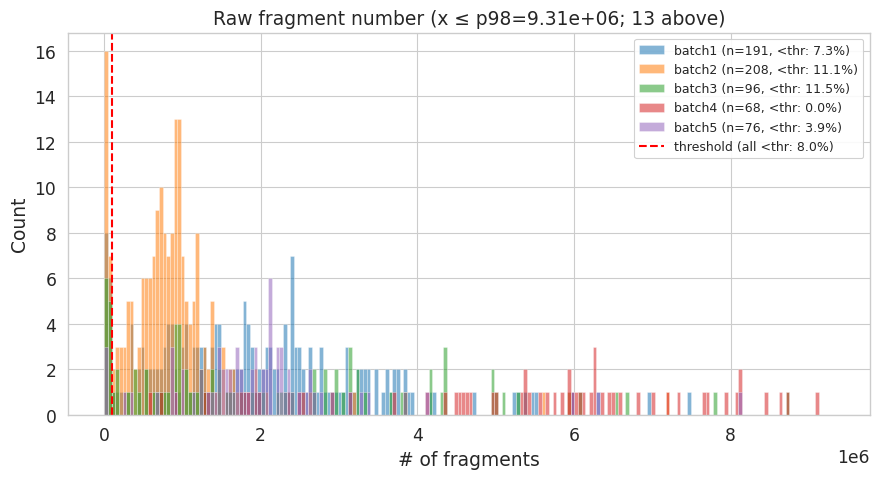

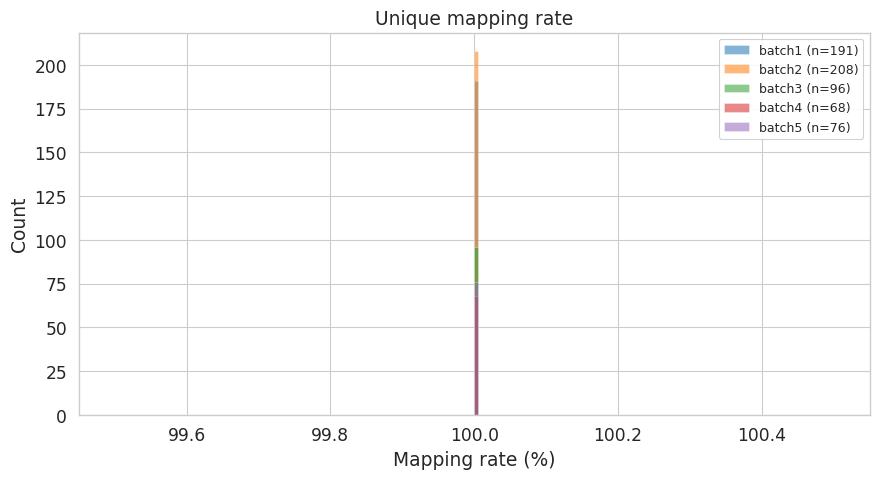

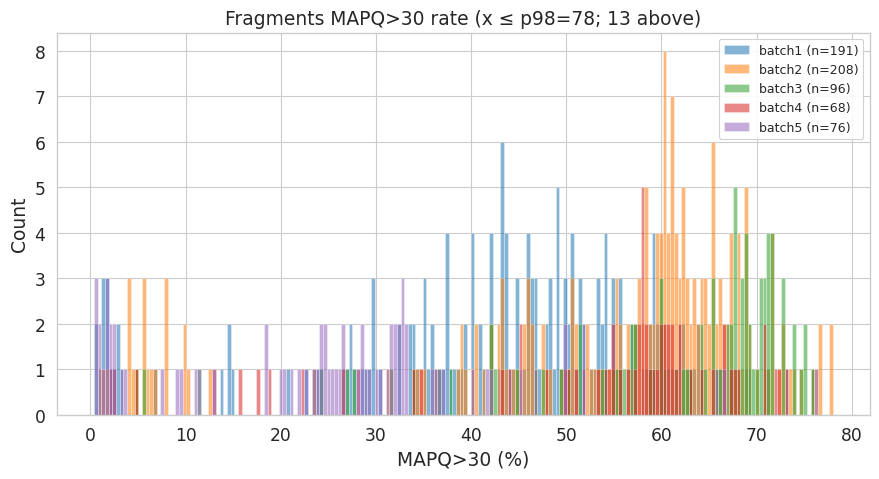

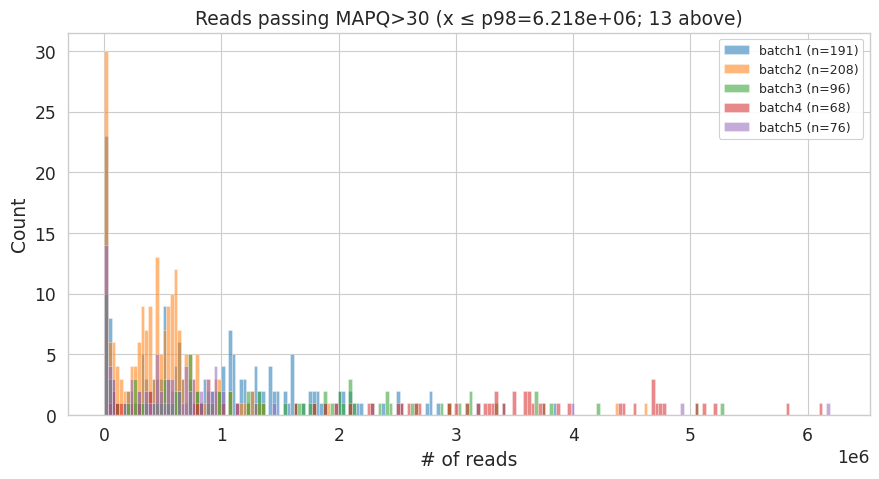

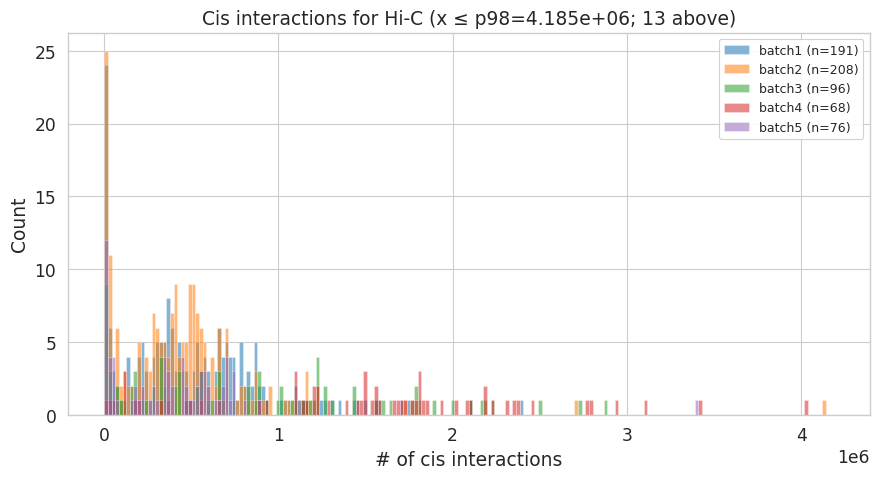

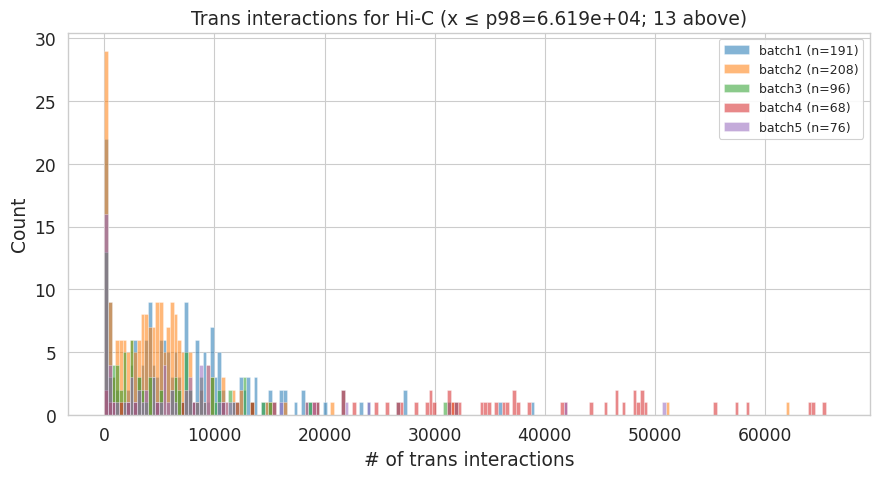

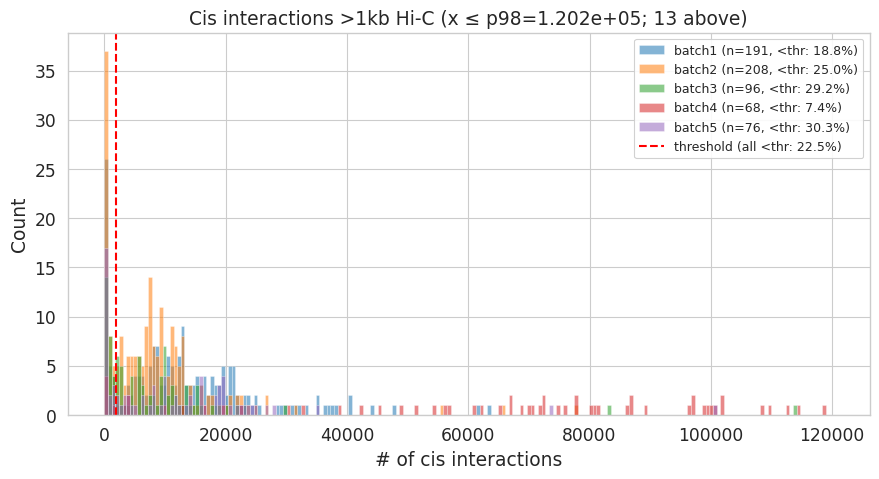

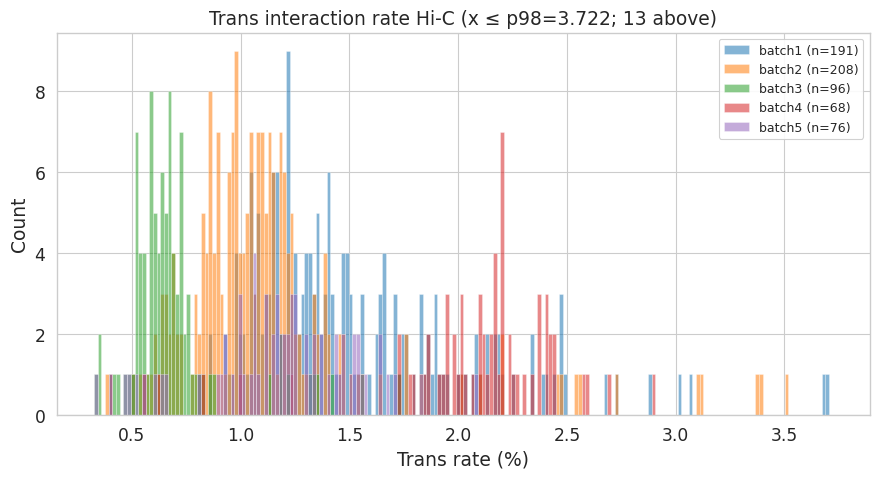

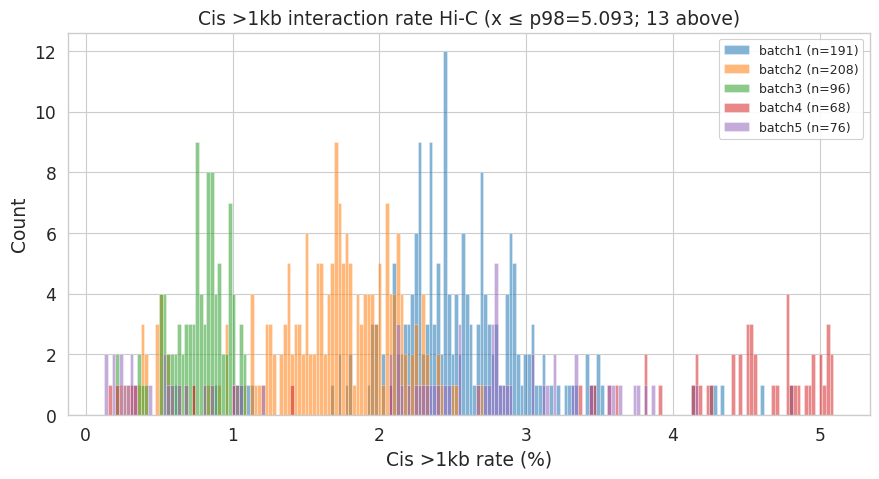

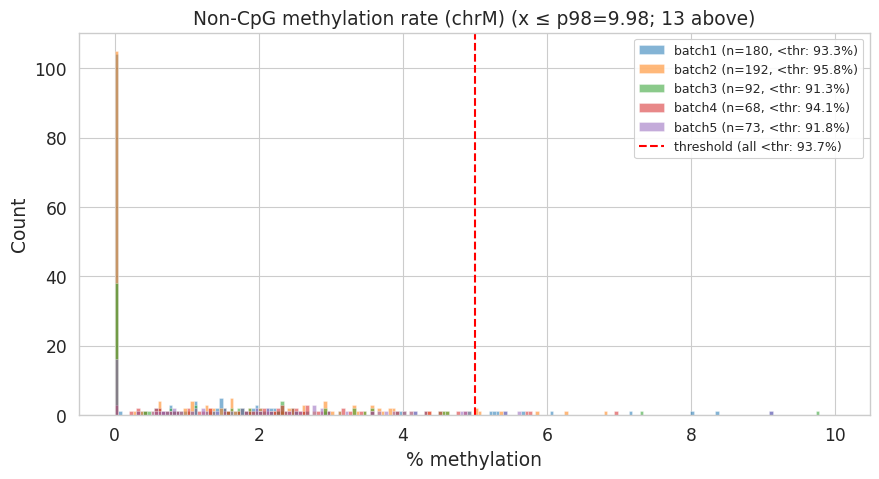

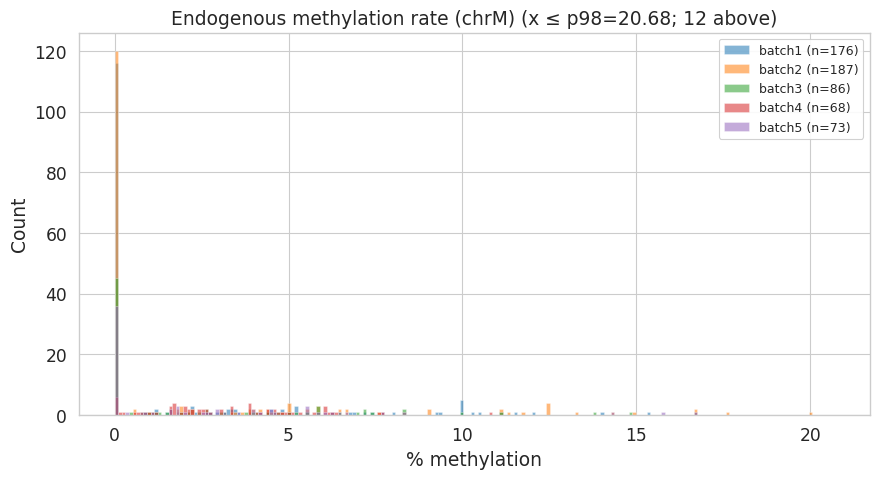

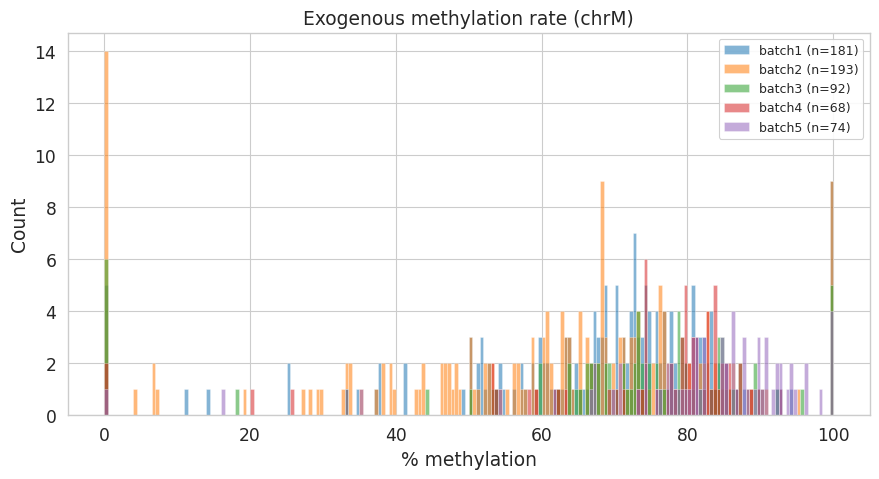

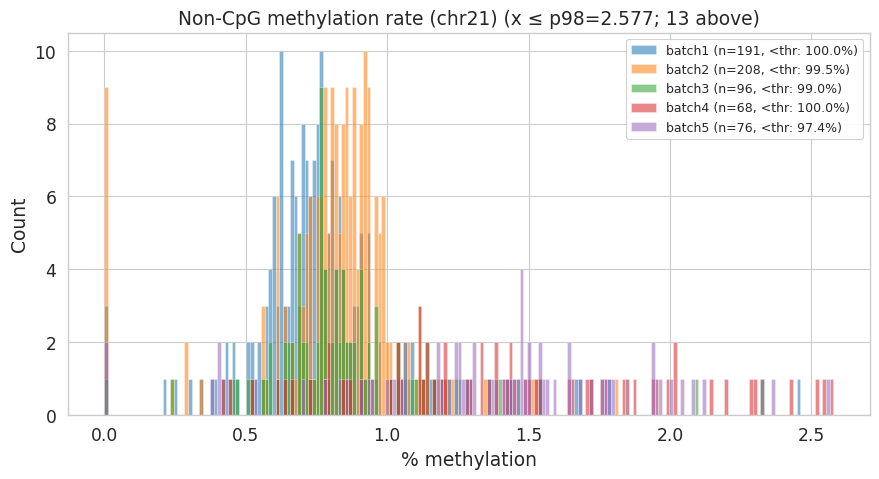

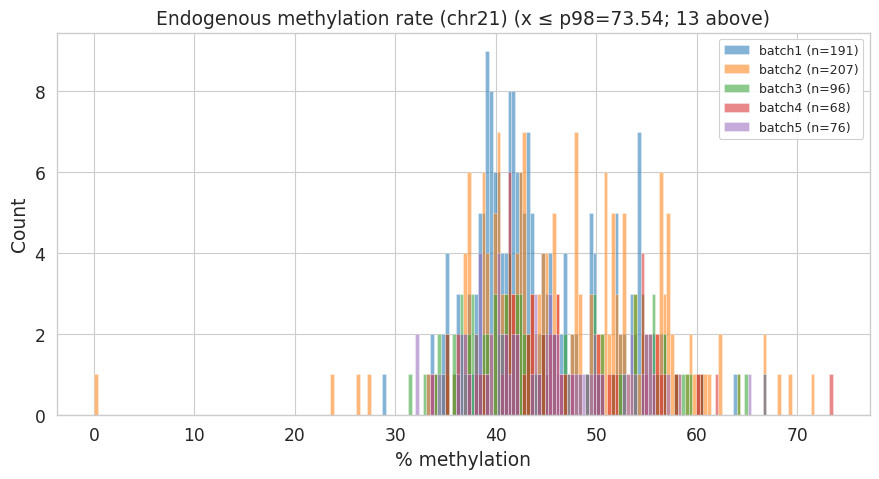

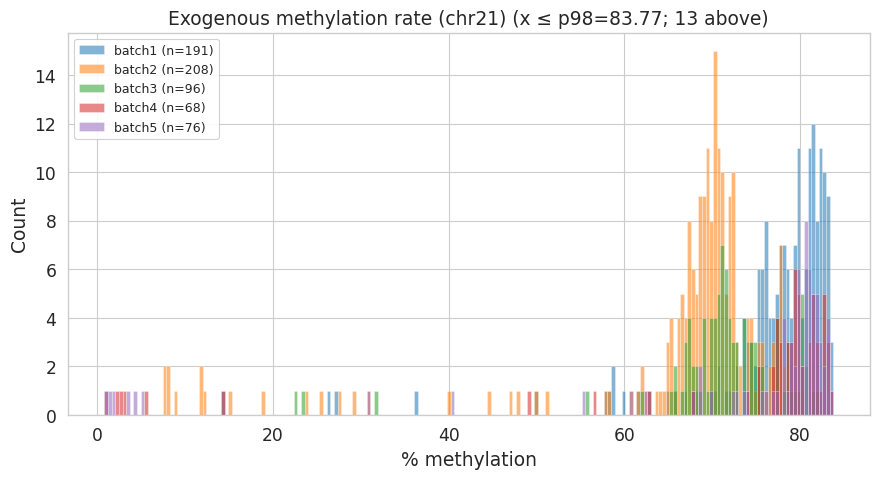

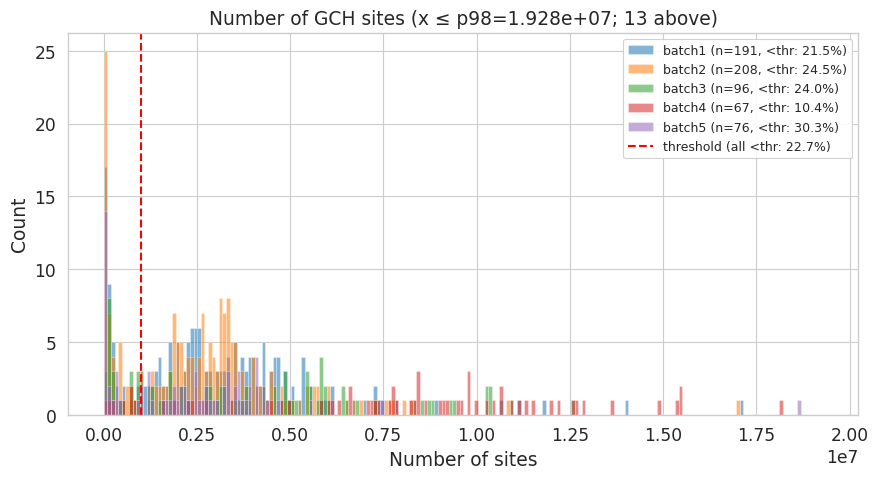

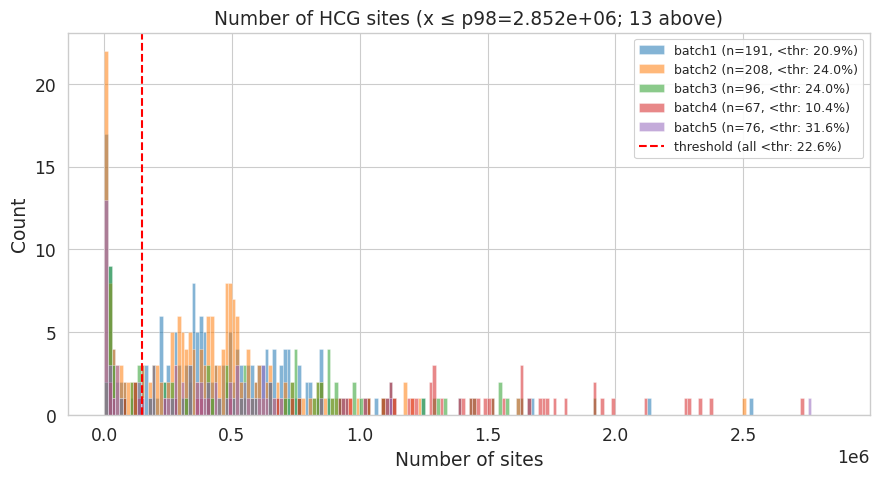

✅ Saved per-batch overlay histograms: /gpfs/projects/b1198/epifluidlab/yoshii/sc_nomehic_cellline/snakemake/figures/cellline_summary_by_batch_p99_if_outlier.pdf


In [ ]:
# Per-batch histograms: one panel per metric, batches overlaid by color
PLOT_COLUMNS = [
    ('fragnum', 'Raw fragment number', '# of fragments'),
    ('uniquemap', 'Unique mapping rate', 'Mapping rate (%)'),
    ('mapq30rate', 'Fragments MAPQ>30 rate', 'MAPQ>30 (%)'),
    ('mapq30num', 'Reads passing MAPQ>30', '# of reads'),
    ('cisnum', 'Cis interactions for Hi-C', '# of cis interactions'),
    ('transnum', 'Trans interactions for Hi-C', '# of trans interactions'),
    ('cis1kbnum', 'Cis interactions >1kb Hi-C', '# of cis interactions'),
    ('transrate', 'Trans interaction rate Hi-C', 'Trans rate (%)'),
    ('cis1kbrate', 'Cis >1kb interaction rate Hi-C', 'Cis >1kb rate (%)'),
    ('noncpg_chrM', 'Non-CpG methylation rate (chrM)', '% methylation'),
    ('endo_chrM', 'Endogenous methylation rate (chrM)', '% methylation'),
    ('exo_chrM', 'Exogenous methylation rate (chrM)', '% methylation'),
    ('noncpg', 'Non-CpG methylation rate (chr21)', '% methylation'),
    ('endo', 'Endogenous methylation rate (chr21)', '% methylation'),
    ('exo', 'Exogenous methylation rate (chr21)', '% methylation'),
    ('GCH', 'Number of GCH sites', 'Number of sites'),
    ('HCG', 'Number of HCG sites', 'Number of sites'),
]

METRIC_THRESHOLDS = {
    'fragnum': THRESHOLDS['fragnum_threshold'],
    'noncpg': THRESHOLDS['noncpg_threshold'],
    'noncpg_chrM': THRESHOLDS['noncpg_threshold'],
    'GCH': THRESHOLDS['GCH_threshold'],
    'HCG': THRESHOLDS['HCG_threshold'],
    'cis1kbnum': THRESHOLDS['cis1kbnum_threshold'],
}


def plot_histograms_per_batch(
    df,
    plot_columns,
    thresholds,
    batch_order=None,
    out_pdf=None,
    bins=40,
    show_inline=False,
    clip_percentile=None,
    clip_only_if_outlier=False,
):
    """One figure per metric: batches overlaid by color.

    clip_percentile: cap x-axis at this percentile (e.g. 99).
    clip_only_if_outlier: if True, only cap when any values exceed that percentile.
    """
    if 'batch' not in df.columns:
        df = df.copy()
        df['batch'] = df['prefix'].str.split('_').str[0]
    if batch_order is None:
        batch_order = sorted(df['batch'].dropna().unique())

    batch_colors = dict(
        zip(
            batch_order,
            sns.color_palette('tab10', n_colors=max(len(batch_order), 1)),
        )
    )

    pdf = PdfPages(out_pdf) if out_pdf else None
    try:
        for col, title, xlabel in plot_columns:
            fig, ax = plt.subplots(figsize=(9, 5))
            thr = thresholds.get(col)

            all_vals = df[col].dropna()
            if all_vals.empty:
                plt.close(fig)
                continue

            title_use = title
            x_hi = None
            apply_clip = False
            if clip_percentile is not None:
                x_hi = float(np.percentile(all_vals, clip_percentile))
                n_above = int((all_vals > x_hi).sum())
                apply_clip = (n_above > 0) if clip_only_if_outlier else True
                if apply_clip:
                    x_lo = all_vals.min()
                    bin_edges = np.linspace(x_lo, x_hi, bins + 1)
                    if n_above > 0:
                        title_use = (
                            f"{title} (x ≤ p{clip_percentile:.0f}={x_hi:.4g}; "
                            f"{n_above} above)"
                        )
                else:
                    x_hi = None
                    bin_edges = np.histogram_bin_edges(all_vals, bins=bins)
            else:
                bin_edges = np.histogram_bin_edges(all_vals, bins=bins)

            for batch in batch_order:
                vals_full = df.loc[df['batch'] == batch, col].dropna()
                if vals_full.empty:
                    continue
                n_total = len(vals_full)
                if thr is not None and n_total > 0:
                    pct_under = 100.0 * float((vals_full < thr).sum()) / n_total
                    label = f'{batch} (n={n_total}, <thr: {pct_under:.1f}%)'
                else:
                    label = f'{batch} (n={n_total})'

                vals = vals_full
                if apply_clip and x_hi is not None:
                    vals = vals[vals <= x_hi]
                ax.hist(
                    vals,
                    bins=bin_edges,
                    alpha=0.55,
                    color=batch_colors[batch],
                    label=label,
                    edgecolor='white',
                    linewidth=0.4,
                )

            if thr is not None and (not apply_clip or thr <= x_hi):
                all_n = len(all_vals)
                pct_under_all = 100.0 * float((all_vals < thr).sum()) / all_n if all_n else 0.0
                ax.axvline(
                    thr,
                    color='red',
                    linestyle='--',
                    linewidth=1.5,
                    label=f'threshold (all <thr: {pct_under_all:.1f}%)',
                )

            ax.set_title(title_use)
            ax.set_xlabel(xlabel)
            ax.set_ylabel('Count')
            ax.legend(loc='best', fontsize=9, framealpha=0.9)
            fig.tight_layout()

            if pdf is not None:
                pdf.savefig(fig, bbox_inches='tight')
            if show_inline:
                plt.show()
            plt.close(fig)
    finally:
        if pdf is not None:
            pdf.close()

    if out_pdf is not None:
        print(f'✅ Saved per-batch overlay histograms: {out_pdf}')


if 'batch' not in df_all_cellline.columns:
    df_all_cellline['batch'] = df_all_cellline['prefix'].str.split('_').str[0]

batch_order = sorted(df_all_cellline['batch'].unique())

# # Full range
# plot_histograms_per_batch(
#     df_all_cellline,
#     PLOT_COLUMNS,
#     METRIC_THRESHOLDS,
#     batch_order=batch_order,
#     out_pdf=OUT_FIG / 'cellline_summary_by_batch.pdf',
#     show_inline=False,
# )

# # Always cap x-axis at 99th percentile
# plot_histograms_per_batch(
#     df_all_cellline,
#     PLOT_COLUMNS,
#     METRIC_THRESHOLDS,
#     batch_order=batch_order,
#     out_pdf=OUT_FIG / 'cellline_summary_by_batch_p99.pdf',
#     clip_percentile=99,
#     clip_only_if_outlier=False,
#     show_inline=True,
# )

# Cap at p99 only when outliers exist (values above p99)
plot_histograms_per_batch(
    df_all_cellline,
    PLOT_COLUMNS,
    METRIC_THRESHOLDS,
    batch_order=batch_order,
    out_pdf=OUT_FIG / 'cellline_summary_by_batch_p99_if_outlier.pdf',
    clip_percentile=98,
    clip_only_if_outlier=True,
    show_inline=True,
    bins=200
)


In [ ]:
def plot_violins_per_batch(
    df,
    plot_columns,
    thresholds,
    batch_order=None,
    out_pdf=None,
    show_inline=False,
    clip_percentile=None,
    clip_only_if_outlier=False,
):
    """One figure per metric: violin plot across batches."""

    if 'batch' not in df.columns:
        df = df.copy()
        df['batch'] = df['prefix'].str.split('_').str[0]

    if batch_order is None:
        batch_order = sorted(df['batch'].dropna().unique())

    pdf = PdfPages(out_pdf) if out_pdf else None

    try:
        for col, title, ylabel in plot_columns:
            if col not in df.columns:
                continue

            plot_df = df[['batch', col]].dropna().copy()
            plot_df = plot_df[plot_df['batch'].isin(batch_order)]

            if plot_df.empty:
                continue

            thr = thresholds.get(col)
            title_use = title

            if clip_percentile is not None:
                x_hi = float(np.percentile(plot_df[col], clip_percentile))
                n_above = int((plot_df[col] > x_hi).sum())

                apply_clip = (n_above > 0) if clip_only_if_outlier else True

                if apply_clip:
                    plot_df = plot_df[plot_df[col] <= x_hi]
                    title_use = (
                        f"{title} (≤ p{clip_percentile:.0f}={x_hi:.4g}; "
                        f"{n_above} above)"
                    )

            fig, ax = plt.subplots(figsize=(10, 5))

            sns.violinplot(
                data=plot_df,
                x='batch',
                y=col,
                order=batch_order,
                inner='box',
                cut=0,
                linewidth=1,
                ax=ax,
            )

            sns.stripplot(
                data=plot_df,
                x='batch',
                y=col,
                order=batch_order,
                color='black',
                size=1.5,
                alpha=0.25,
                jitter=0.25,
                ax=ax,
            )

            if thr is not None:
                all_vals = df[col].dropna()
                pct_under_all = 100.0 * (all_vals < thr).sum() / len(all_vals)

                ax.axhline(
                    thr,
                    color='red',
                    linestyle='--',
                    linewidth=1.5,
                    label=f'threshold (all <thr: {pct_under_all:.1f}%)',
                )
                ax.legend(loc='best', fontsize=9)

            ax.set_title(title_use)
            ax.set_xlabel('Batch')
            ax.set_ylabel(ylabel)
            ax.tick_params(axis='x', rotation=45)
            fig.tight_layout()

            if pdf is not None:
                pdf.savefig(fig, bbox_inches='tight')

            if show_inline:
                plt.show()

            plt.close(fig)

    finally:
        if pdf is not None:
            pdf.close()

    if out_pdf is not None:
        print(f'✅ Saved per-batch violin plots: {out_pdf}')

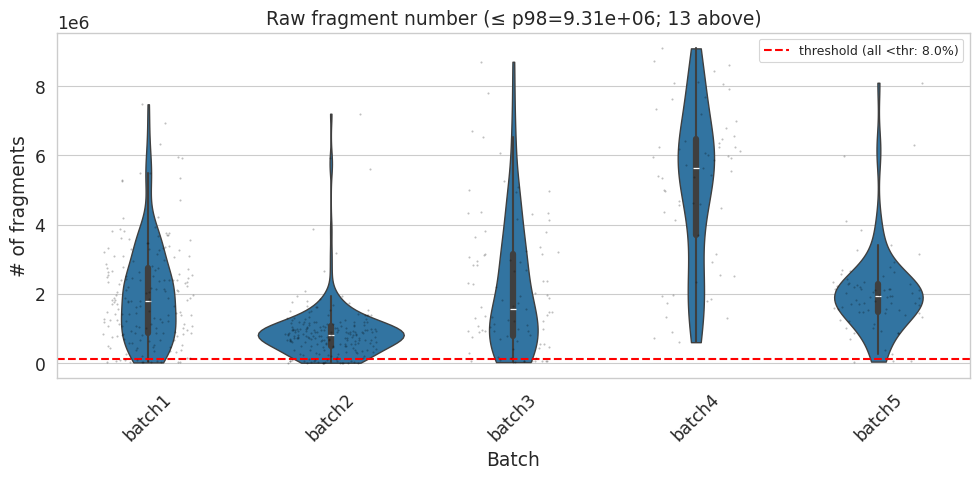

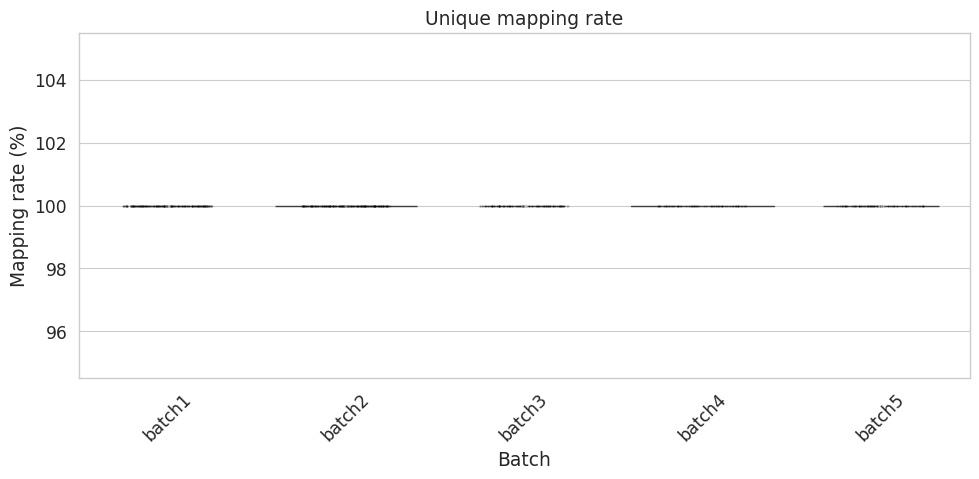

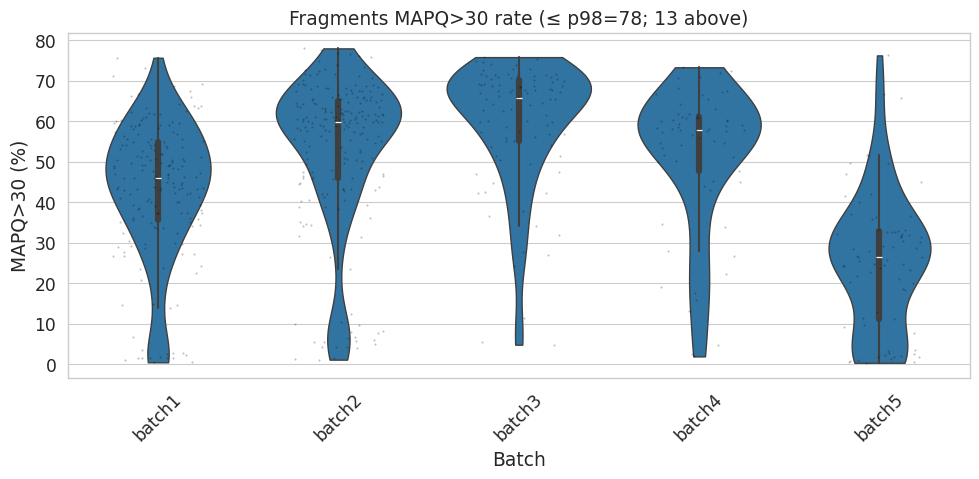

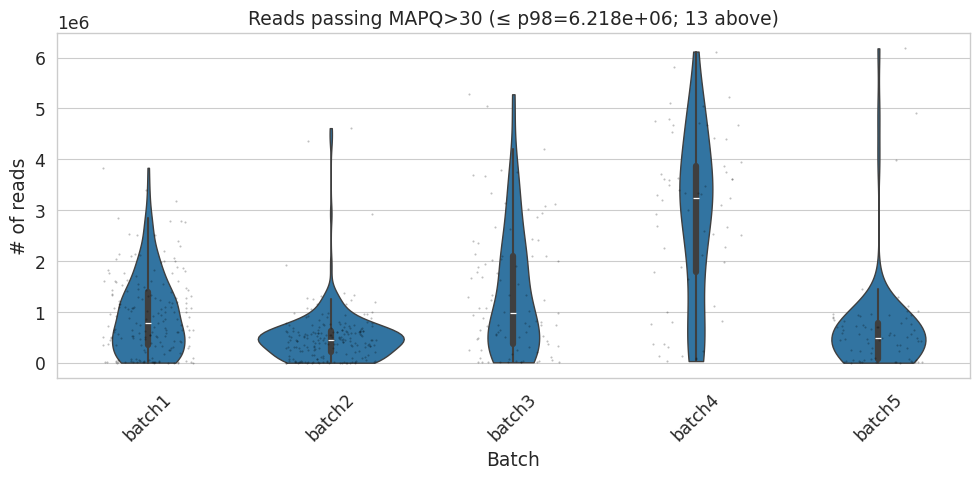

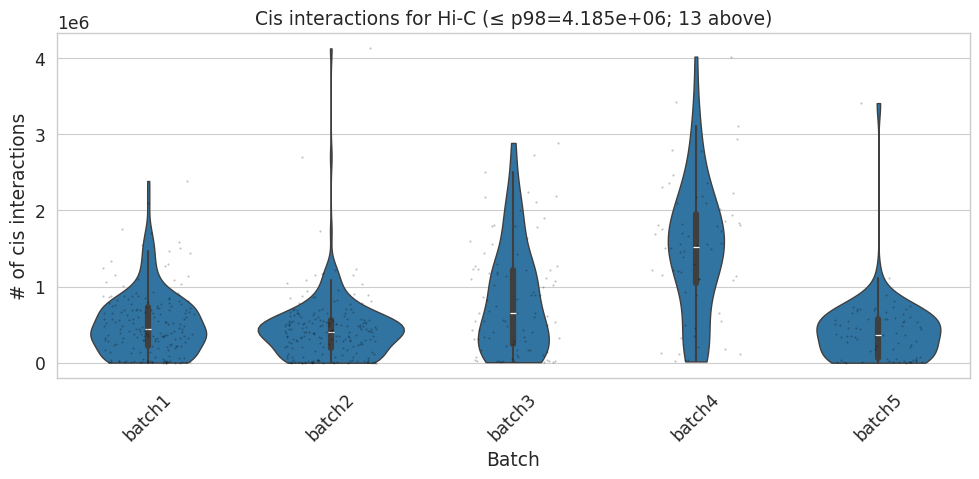

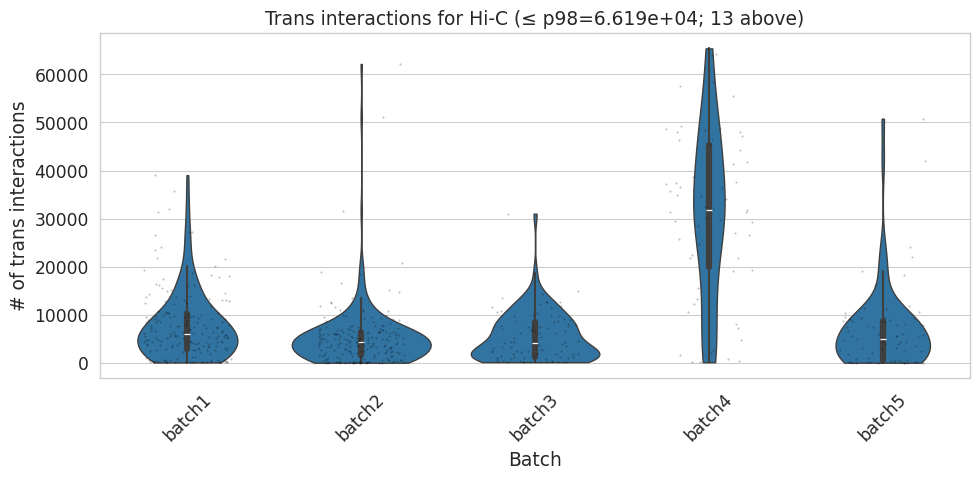

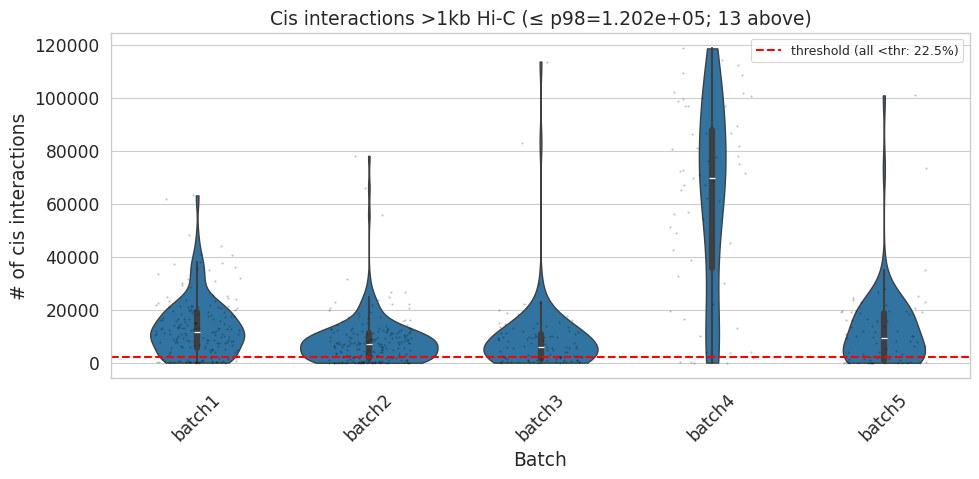

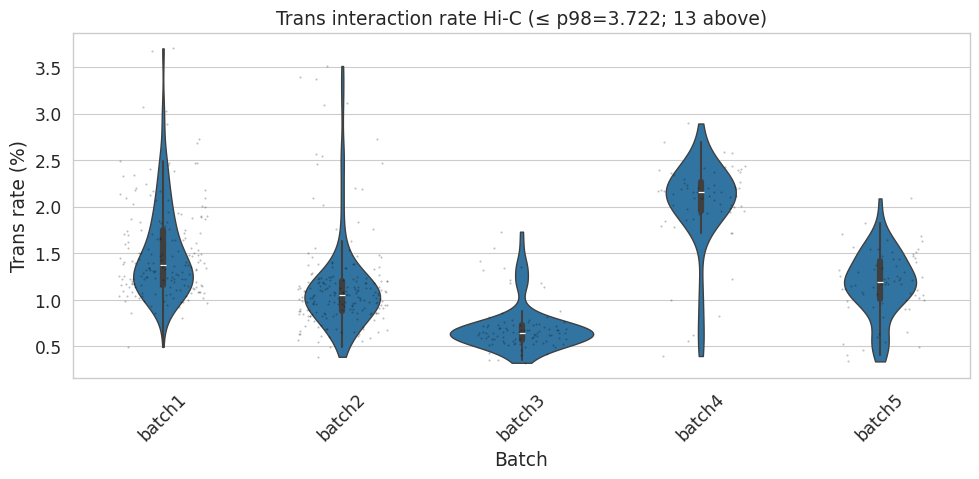

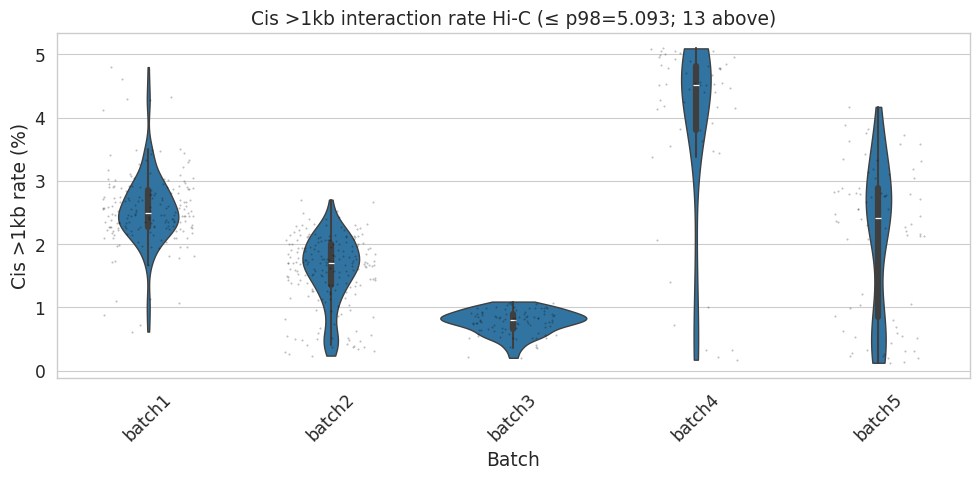

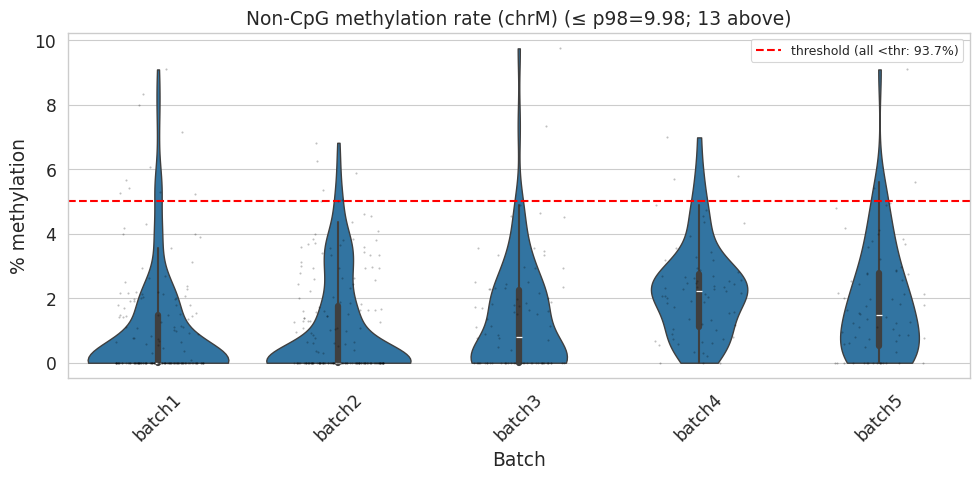

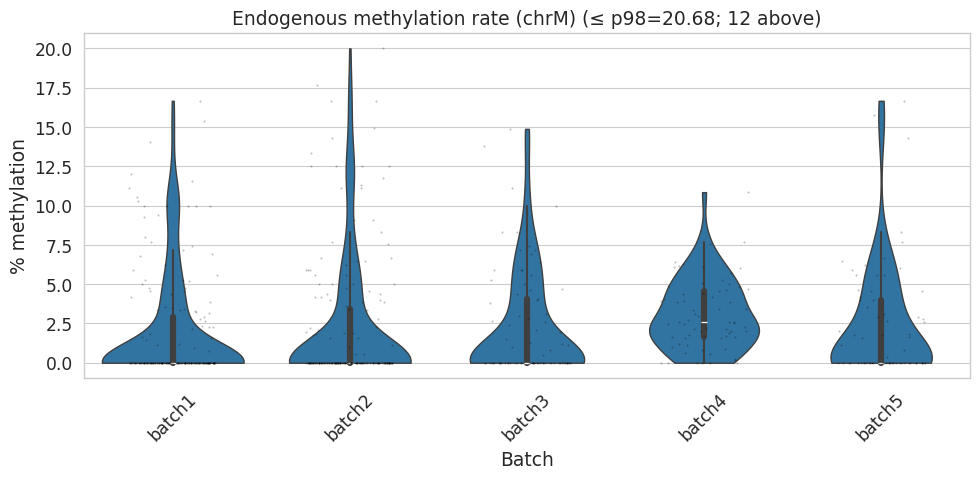

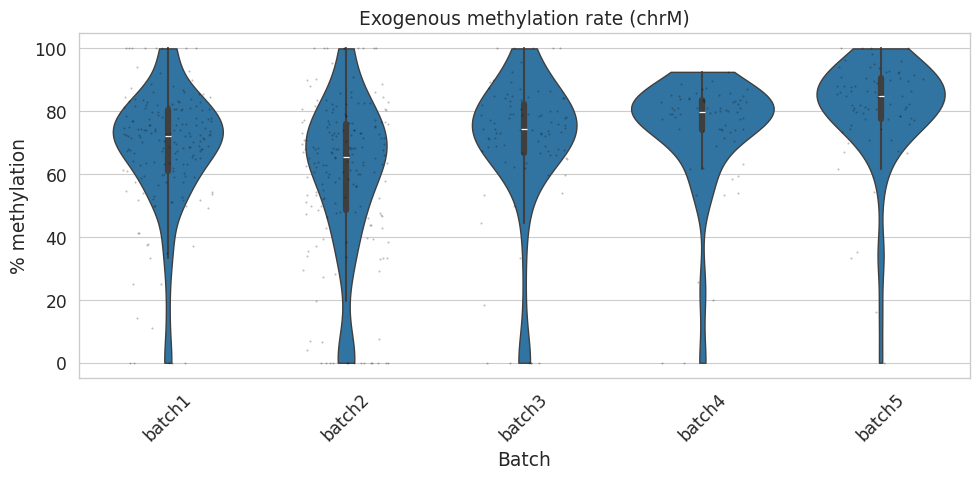

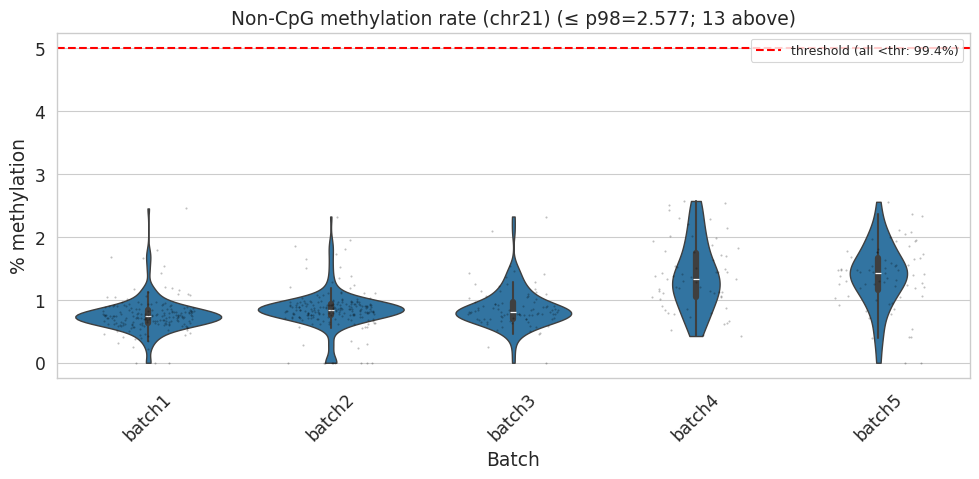

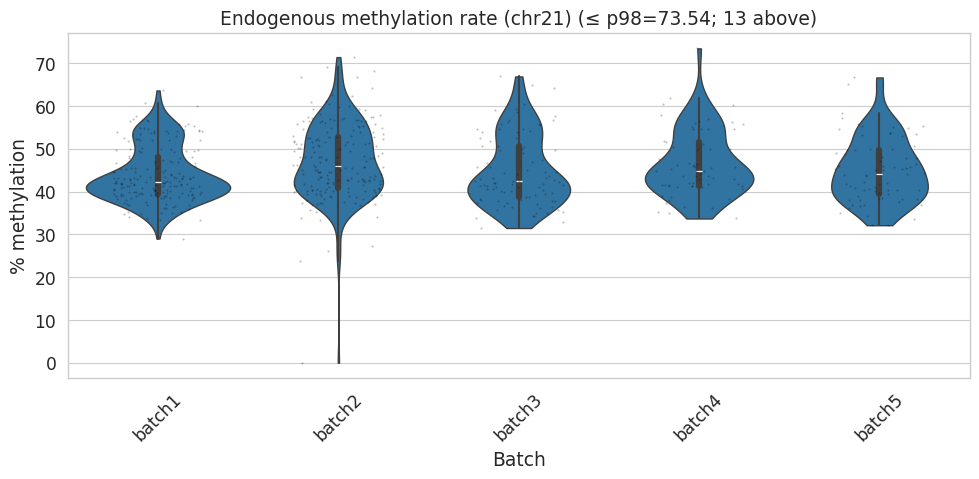

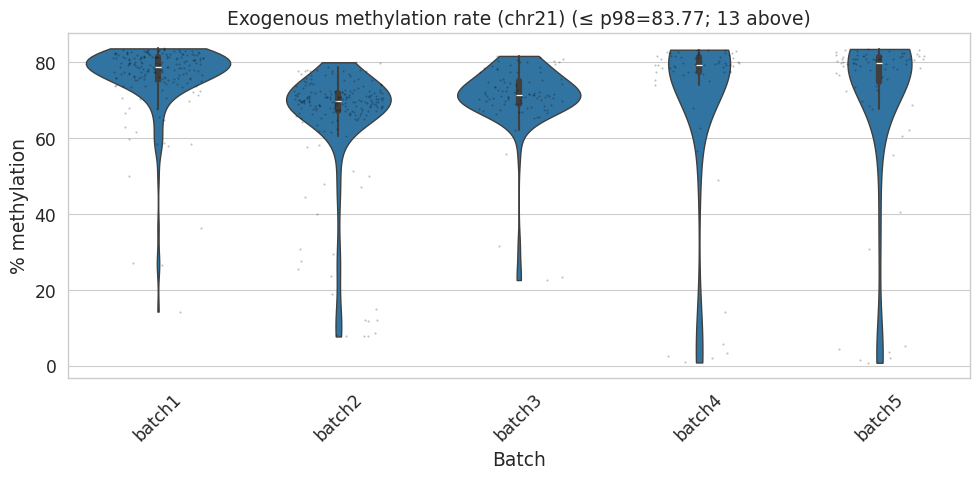

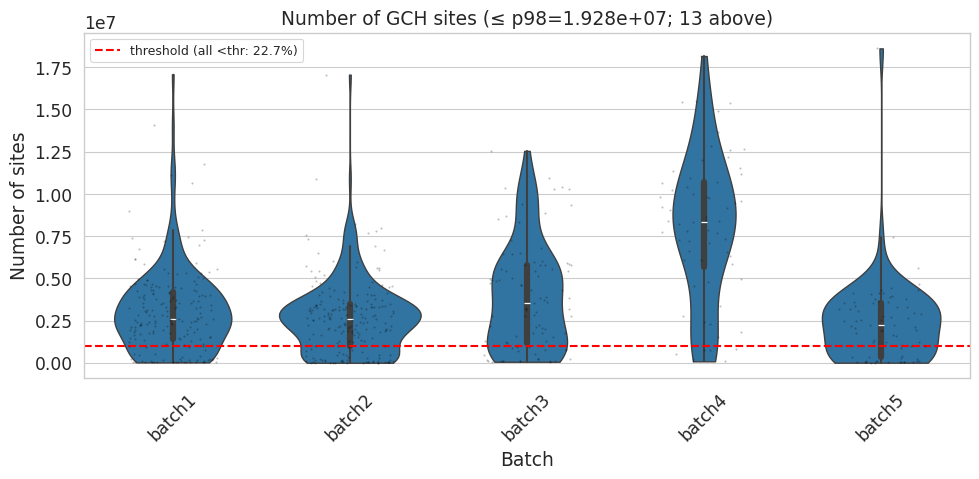

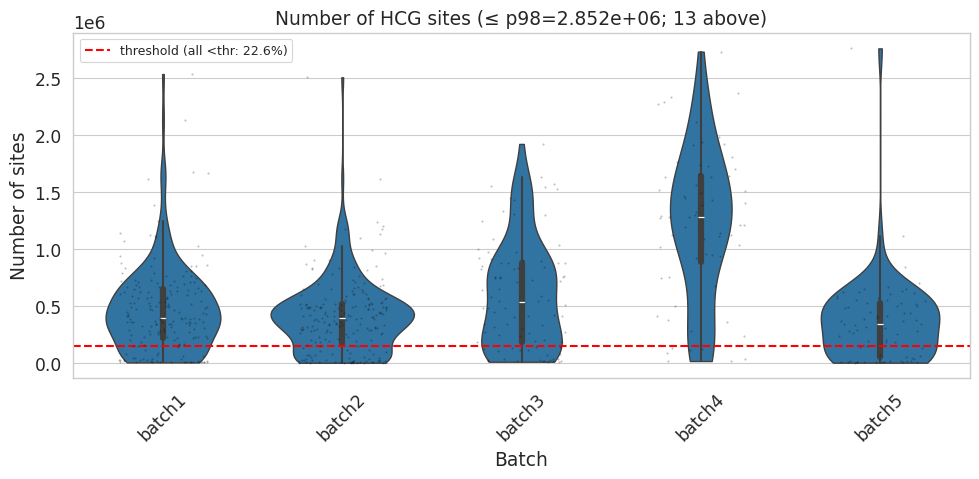

✅ Saved per-batch violin plots: /gpfs/projects/b1198/epifluidlab/yoshii/sc_nomehic_cellline/snakemake/figures/cellline_summary_by_batch_violin_p98_if_outlier.pdf


In [ ]:
plot_violins_per_batch(
    df_all_cellline,
    PLOT_COLUMNS,
    METRIC_THRESHOLDS,
    batch_order=batch_order,
    out_pdf=OUT_FIG / 'cellline_summary_by_batch_violin_p98_if_outlier.pdf',
    clip_percentile=98,
    clip_only_if_outlier=True,
    show_inline=True,
)

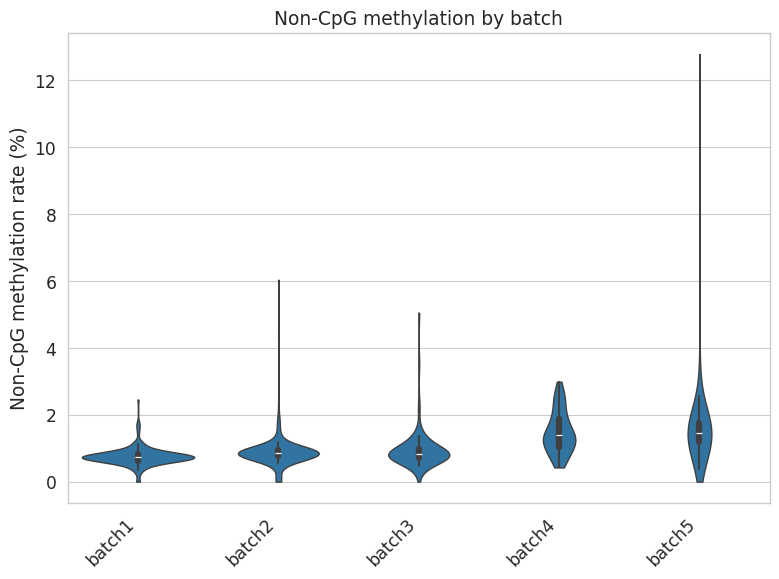

In [ ]:
# Publication-style violin: non-CpG methylation by batch
sns.set_context('paper', font_scale=1.4)
sns.set_style('whitegrid')
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['ps.fonttype'] = 42

plot_df = df_all_cellline.dropna(subset=['noncpg']).copy()
batch_order = sorted(plot_df['batch'].unique())

plt.figure(figsize=(8, 6))
ax = sns.violinplot(data=plot_df, x='batch', y='noncpg', order=batch_order, inner='box', cut=0)
ax.set_xlabel('')
ax.set_ylabel('Non-CpG methylation rate (%)')
ax.set_title('Non-CpG methylation by batch')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig(OUT_FIG / 'noncpg_by_batch.pdf', dpi=300)
plt.savefig(OUT_FIG / 'noncpg_by_batch.png', dpi=300)
plt.show()

## Cell × bin methylation matrices (all bin labels in `config.yaml`)

Build dense matrices from `08.methylation_snakemake/*.{GCH,HCG}.<label>_methylation.txt.gz`. The list of bin labels comes from `config.yaml`:
- fixed-size bins → `methylation_bin_sizes` (e.g. 1000 → `1kb`, 250000 → `250kb`)
- custom regions → `methylation_region_beds` keys (e.g. `gene_tss`, `gene_body`)

Each output is `QC/methylation_matrices/methylation_matrix_<context>_<label>.tsv.gz` plus a `bins_<label>.tsv` coord file.
- **rows** = cells
- **columns** = `bin_id`
- **values** = `methylation_level`

Skips any matrix that is already on disk AND newer than the newest per-cell input (incremental rebuild). Set `USE_QC_PASSED_ONLY = True` to restrict to `cellline_passed.txt`. Set `FORCE_REBUILD = True` to overwrite existing matrices.

In [ ]:
import yaml

CONFIG_PATH = WORKDIR / 'config.yaml'
METH_BIN_DIR = WORKDIR / '08.methylation_snakemake'
OUT_MATRIX = OUT_QC / 'methylation_matrices'
OUT_MATRIX.mkdir(exist_ok=True)

# Knobs
USE_QC_PASSED_ONLY = False
FORCE_REBUILD      = False

# --- Load bin labels from config.yaml ---
cfg = yaml.safe_load(open(CONFIG_PATH))
def _bin_size_to_label(n):
    """Mirror sc_NOMeHiC_pipeline/Snakefile _bin_size_to_label."""
    n = int(n)
    if n >= 1_000_000 and n % 1_000_000 == 0: return f"{n // 1_000_000}Mb"
    if n >= 1000 and n % 1000 == 0:           return f"{n // 1000}kb"
    return f"{n}bp"
SIZE_LABELS   = [_bin_size_to_label(n) for n in cfg.get('methylation_bin_sizes', [])]
REGION_LABELS = list((cfg.get('methylation_region_beds') or {}).keys())
ALL_LABELS    = SIZE_LABELS + REGION_LABELS
CONTEXTS      = ['GCH', 'HCG']
print(f'config.yaml -> fixed bins: {SIZE_LABELS}')
print(f'config.yaml -> regions:    {REGION_LABELS}')
print(f'contexts:                  {CONTEXTS}')

# --- helpers ---
def _cell_from_methylation_path(path, context, bin_label):
    suffix = f'.{context}.{bin_label}_methylation.txt.gz'
    return Path(path).name[: -len(suffix)]

def build_methylation_matrix(context, bin_label, meth_dir=METH_BIN_DIR, cells=None):
    """Return cells × bins matrix of methylation_level."""
    pattern = f'*.{context}.{bin_label}_methylation.txt.gz'
    files = sorted(meth_dir.glob(pattern))
    if not files:
        raise FileNotFoundError(f'No files matching {pattern} in {meth_dir}')
    if cells is not None:
        cells = set(cells)
        files = [f for f in files if _cell_from_methylation_path(f, context, bin_label) in cells]
    rows = []
    for path in tqdm(files, desc=f'{context} {bin_label}'):
        cell = _cell_from_methylation_path(path, context, bin_label)
        df = pd.read_csv(path, sep='\t', usecols=['bin_id', 'methylation_level'])
        rows.append(df.set_index('bin_id')['methylation_level'].rename(cell))
    mat = pd.concat(rows, axis=1).T
    mat.index.name = 'cell'
    return mat

def save_bin_coords(meth_dir, bin_label, out_path):
    """Save bin coordinates once (same across cells)."""
    ref = next(meth_dir.glob(f'*.GCH.{bin_label}_methylation.txt.gz'))
    coords = pd.read_csv(ref, sep='\t', usecols=['bin_id', 'chr', 'start', 'end'])
    coords.to_csv(out_path, sep='\t', index=False)
    return coords

def newest_input_mtime(meth_dir, context, bin_label):
    files = sorted(meth_dir.glob(f'*.{context}.{bin_label}_methylation.txt.gz'))
    if not files:
        return -1
    return max(f.stat().st_mtime for f in files)

# --- cell whitelist (optional) ---
cells_filter = None
if USE_QC_PASSED_ONLY:
    passed_path = OUT_QC / 'cellline_passed.txt'
    if passed_path.exists():
        cells_filter = pd.read_csv(passed_path, header=None)[0].tolist()
        print(f'Filtering to {len(cells_filter)} QC-passed cells')
    else:
        print('⚠️ cellline_passed.txt not found; using all cells')

# --- build / refresh each (context × label) matrix ---
for label in ALL_LABELS:
    bin_coords_path = OUT_MATRIX / f'bins_{label}.tsv'
    if FORCE_REBUILD or not bin_coords_path.exists():
        try:
            save_bin_coords(METH_BIN_DIR, label, bin_coords_path)
            print(f'Saved bin coordinates: {bin_coords_path}')
        except StopIteration:
            print(f'⚠️ no per-cell files for label={label}; skipping')
            continue

    for context in CONTEXTS:
        out_file = OUT_MATRIX / f'methylation_matrix_{context}_{label}.tsv.gz'
        in_mtime = newest_input_mtime(METH_BIN_DIR, context, label)
        if in_mtime < 0:
            print(f'⚠️ no per-cell files for {context}/{label}; skipping')
            continue
        if (not FORCE_REBUILD) and out_file.exists() and out_file.stat().st_mtime > in_mtime:
            print(f'✓ {context} {label}: up-to-date ({out_file.stat().st_size / 1e6:.1f} MB)')
            continue
        mat = build_methylation_matrix(context, label, cells=cells_filter)
        mat.to_csv(out_file, sep='\t', compression='gzip')
        print(f'✅ {context} {label}: {mat.shape[0]} cells × {mat.shape[1]} bins -> '
              f'{out_file} ({out_file.stat().st_size / 1e6:.1f} MB)')
